In [6]:

import pandas as pd

df = pd.read_csv("cases_coverage_ms.csv")

print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (1163, 18)


,year,state,measles_cases,mumps_cases,pertussis_cases,measles_coverage_pct,measles_n,measles_n_vaccinated,mumps_coverage_pct,mumps_n,mumps_n_vaccinated,pertussis_coverage_pct,pertussis_n,pertussis_n_vaccinated,population,measles_cases_per_100k,mumps_cases_per_100k,pertussis_cases_per_100k
0,1995,AK,NaN,13.0,1.0,89.86,194.0,177.0,89.86,194.0,177.0,77.58,194.0,159.0,604412.0,NaN,2.150851,0.165450
1,1996,AK,63.0,3.0,4.0,84.55,260.0,225.0,84.55,260.0,225.0,78.25,260.0,210.0,608569.0,10.352154,0.492960,0.657280
2,1997,AK,48.0,4.0,14.0,87.41,291.0,257.0,87.41,291.0,257.0,80.98,291.0,242.0,612968.0,7.830751,0.652563,2.283969
3,1998,AK,29.0,2.0,15.0,87.06,34.0,30.0,87.06,34.0,30.0,82.01,34.0,28.0,619932.0,4.677932,0.322616,2.419620
4,1999,AK,29.0,3.0,5.0,90.67,349.0,321.0,90.67,349.0,321.0,83.54,349.0,296.0,624779.0,4.641641,0.480170,0.800283


In [7]:

# Select California and Florida
ca_fl = df[df["state"].isin(["CA", "FL"])].copy()

# Sort by state and year
ca_fl = ca_fl.sort_values(["state", "year"])

print(ca_fl.groupby("state").size())

# Display the selected data
display(ca_fl[[
    "year",
    "state",
    "measles_cases",
    "measles_coverage_pct"
]])


state
CA    23
FL    23
dtype: int64


,year,state,measles_cases,measles_coverage_pct
92,1995,CA,108.0,90.32
93,1996,CA,46.0,90.73
94,1997,CA,23.0,89.40
95,1998,CA,8.0,92.59
96,1999,CA,17.0,93.02
97,2000,CA,15.0,90.89
98,2001,CA,36.0,91.60
99,2002,CA,3.0,91.07
100,2003,CA,5.0,93.43
101,2004,CA,6.0,93.91


In [8]:

# Check missing values for California and Florida
columns = [
    "measles_cases",
    "measles_coverage_pct",
    "population"
]

print("Missing values by state:")
print(ca_fl.groupby("state")[columns].apply(
    lambda x: x.isna().sum()
))

print("\nAvailable observations by state:")
print(ca_fl.groupby("state")[columns].count())


Missing values by state:
       measles_cases  measles_coverage_pct  population
state                                                 
CA                 0                     0           0
FL                 5                     0           0

Available observations by state:
       measles_cases  measles_coverage_pct  population
state                                                 
CA                23                    23          23
FL                18                    23          23


In [9]:

# Calculate measles incidence per 100,000 people
ca_fl["measles_per_100k"] = (
    ca_fl["measles_cases"] / ca_fl["population"]
) * 100000

# Display the results
display(ca_fl[[
    "year",
    "state",
    "measles_cases",
    "population",
    "measles_per_100k",
    "measles_coverage_pct"
]].head(10))


,year,state,measles_cases,population,measles_per_100k,measles_coverage_pct
92,1995,CA,108.0,31696582.0,0.340731,90.32
93,1996,CA,46.0,32018834.0,0.143665,90.73
94,1997,CA,23.0,32486010.0,0.070800,89.40
95,1998,CA,8.0,32987675.0,0.024251,92.59
96,1999,CA,17.0,33499204.0,0.050747,93.02
97,2000,CA,15.0,33987977.0,0.044133,90.89
98,2001,CA,36.0,34479458.0,0.104410,91.60
99,2002,CA,3.0,34871843.0,0.008603,91.07
100,2003,CA,5.0,35253159.0,0.014183,93.43
101,2004,CA,6.0,35574576.0,0.016866,93.91


In [10]:

from scipy.stats import pearsonr
import pandas as pd

results = []

for state in ["CA", "FL"]:
    state_df = ca_fl[ca_fl["state"] == state].copy()

    for lag in range(6):
        # Vaccination coverage in the starting year
        coverage = state_df[[
            "year", "measles_coverage_pct"
        ]].copy()

        # Match incidence from 'lag' years later
        incidence = state_df[[
            "year", "measles_per_100k"
        ]].copy()

        incidence["year"] = incidence["year"] - lag

        matched = coverage.merge(incidence, on="year")
        matched = matched.dropna(
            subset=["measles_coverage_pct", "measles_per_100k"]
        )

        n = len(matched)

        if n >= 3 and (
            matched["measles_coverage_pct"].nunique() > 1
        ) and (
            matched["measles_per_100k"].nunique() > 1
        ):
            r, p = pearsonr(
                matched["measles_coverage_pct"],
                matched["measles_per_100k"]
            )
        else:
            r, p = float("nan"), float("nan")

        results.append({
            "state": state,
            "lag_years": lag,
            "n": n,
            "pearson_r": r,
            "p_value": p
        })

lag_results = pd.DataFrame(results)

display(lag_results.round(4))


,state,lag_years,n,pearson_r,p_value
0,CA,0,23,-0.2169,0.3202
1,CA,1,22,-0.2749,0.2157
2,CA,2,21,-0.2568,0.2611
3,CA,3,20,0.1199,0.6145
4,CA,4,19,0.1035,0.6732
5,CA,5,18,-0.0236,0.9259
6,FL,0,18,-0.1985,0.4297
7,FL,1,17,-0.0629,0.8104
8,FL,2,16,0.2352,0.3806
9,FL,3,15,0.5060,0.0543


In [13]:

# Save the updated California and Florida lag results
lag_results.to_csv(
    "CA_FL_updated_lag_results.csv",
    index=False
)



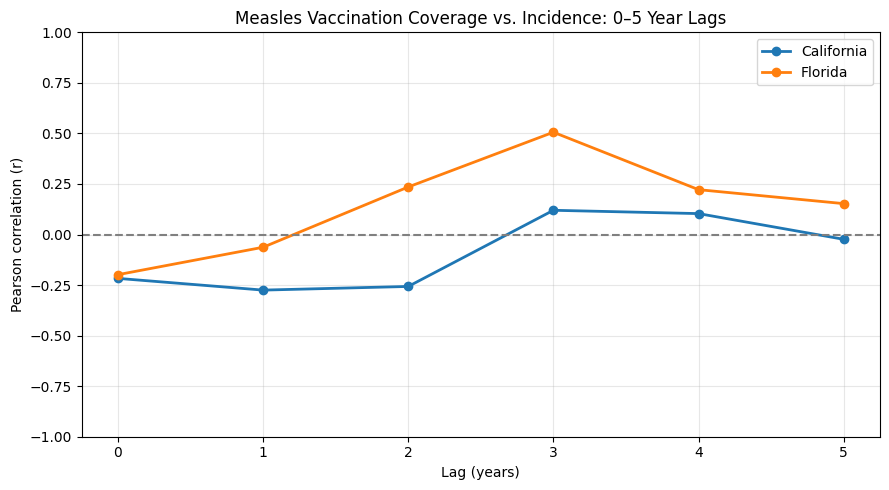

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for state, label in [("CA", "California"), ("FL", "Florida")]:
    data = lag_results[lag_results["state"] == state]

    plt.plot(
        data["lag_years"],
        data["pearson_r"],
        marker="o",
        linewidth=2,
        label=label
    )

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Lag (years)")
plt.ylabel("Pearson correlation (r)")
plt.title("Measles Vaccination Coverage vs. Incidence: 0–5 Year Lags")
plt.xticks(range(6))
plt.ylim(-1, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("CA_FL_lag_correlation.png", dpi=300)
plt.show()


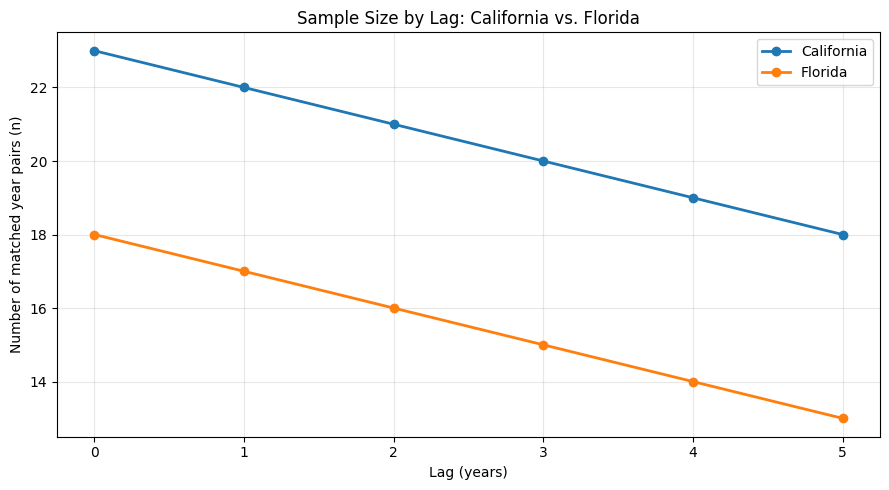

In [14]:

plt.figure(figsize=(9, 5))

for state, label in [("CA", "California"), ("FL", "Florida")]:
    data = lag_results[lag_results["state"] == state]

    plt.plot(
        data["lag_years"],
        data["n"],
        marker="o",
        linewidth=2,
        label=label
    )

plt.xlabel("Lag (years)")
plt.ylabel("Number of matched year pairs (n)")
plt.title("Sample Size by Lag: California vs. Florida")
plt.xticks(range(6))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("CA_FL_lag_sample_sizes.png", dpi=300)
plt.show()
